# Credit card fraud detection

**Goal:** given a card transaction, estimate how likely it is to be fraudulent, so that the riskiest transactions can be sent to an analyst (or blocked) before money is lost.

**How to read this notebook**

1. [Data](#1.-Data): what we have and what is unusual about it.
2. [Evaluation design](#2.-Evaluation-design): how we measure success *before* looking at models.
3. [Exploration](#3.-Exploration): what separates fraud from genuine transactions (training data only).
4. [Models](#4.-Models): logistic regression as an interpretable baseline, then LightGBM.
5. [Test-set results](#5.-Test-set-results): the held-out evaluation, with uncertainty.
6. [Choosing an operating point](#6.-Choosing-an-operating-point): turning scores into alerts with a cost model.
7. [What drives the predictions](#7.-What-drives-the-predictions).
8. [Conclusions and next steps](#8.-Conclusions-and-next-steps).

A written summary of the results is in [`REPORT.md`](REPORT.md).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from lightgbm import LGBMClassifier
from sklearn import set_config
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    TimeSeriesSplit,
    cross_validate,
)
from sklearn.preprocessing import StandardScaler

import fraud_utils as fu

warnings.filterwarnings("ignore", category=UserWarning)
set_config(transform_output="pandas")  # keep column names through pipelines
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)
fu.set_plot_style()

SEED = 42
REVIEW_COST = 5.0  # assumed cost (EUR) for an analyst to review one alert

## 1. Data

The [Kaggle dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) has card transactions made by European cardholders over two days in September 2013. For confidentiality, 28 of the features (`V1`–`V28`) are principal components of the original variables. Only `Time` (seconds since the first transaction) and `Amount` are in their original form. `Class` is 1 for fraud.

`load_data` drops exact duplicate rows. These are almost certainly logging artefacts, and keeping them would let identical rows land on both sides of the train/test split.

In [2]:
raw = pd.read_csv("data/creditcard.csv")
df = fu.load_data("data/creditcard.csv")

pd.Series(
    {
        "transactions": len(df),
        "frauds": int(df["Class"].sum()),
        "fraud rate": f"{df['Class'].mean():.3%}",
        "duplicate rows removed": len(raw) - len(df),
        "missing values": int(df.isna().sum().sum()),
        "time span (hours)": round(df["Time"].max() / 3600, 1),
    },
    name="value",
).to_frame()

,value
transactions,283726
frauds,473
fraud rate,0.167%
duplicate rows removed,1081
missing values,0
time span (hours),48.0


**Fraud is rare: about 1 in 600 transactions.** That shapes everything that follows. A model that never flags anything is 99.8% accurate and useless, so accuracy is out as a metric.

The PCA features are centred at zero but **not** on a common scale: their standard deviations range from about 0.3 to 2. Scale-sensitive models (regularised logistic regression) therefore need all features standardised, not just `Amount`.

In [3]:
v_cols = [f"V{i}" for i in range(1, 29)]
corr = df[v_cols].corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
pd.Series(
    {
        "V-feature mean, max |mean|": df[v_cols].mean().abs().max(),
        "V-feature std, min": df[v_cols].std().min(),
        "V-feature std, max": df[v_cols].std().max(),
        "max |correlation| between V-features": corr.max(),
    },
    name="value",
).to_frame()

,value
"V-feature mean, max |mean|",0.006
"V-feature std, min",0.328
"V-feature std, max",1.948
max |correlation| between V-features,0.019


## 2. Evaluation design

These decisions are made before any modelling, so the results cannot steer them.

**Temporal split.** The model will score *future* transactions, so we train on the earliest 80% of the timeline and test on the latest 20%. A random split mixes past and future, which is optimistic for fraud, where patterns drift. The test set is touched once, in Section 5.

**Model selection uses forward-chaining cross-validation (CV)** inside the training set (`TimeSeriesSplit`, 5 folds). Each fold trains on all transactions up to a point in time and validates on the next block. That is the same "past → future" question the test set asks. Section 5 shows why this matters: the usual shuffled K-fold CV is noticeably optimistic on this data.

**Metric: average precision (AP),** the area under the precision–recall curve. It summarises how well the model ranks frauds above genuine transactions, focusing on the positive class. ROC-AUC looks flattering here because the false-positive *rate* stays tiny even when false positives outnumber frauds. **The no-skill baseline for AP is the fraud rate (≈ 0.0017),** not 0.5.

AP is threshold-free. Section 6 then picks an actual alert threshold using a simple cost model.

In [4]:
X_train, X_test, y_train, y_test = fu.temporal_split(df, test_size=0.2)
cv = TimeSeriesSplit(n_splits=5)  # rows are sorted by Time in load_data

split_table = pd.DataFrame(
    {
        "transactions": [len(y_train), len(y_test)],
        "frauds": [int(y_train.sum()), int(y_test.sum())],
        "fraud rate": [f"{y_train.mean():.3%}", f"{y_test.mean():.3%}"],
        "hours": [
            f"{X_train['Time'].min() / 3600:.0f}–{X_train['Time'].max() / 3600:.0f}",
            f"{X_test['Time'].min() / 3600:.0f}–{X_test['Time'].max() / 3600:.0f}",
        ],
    },
    index=["train", "test"],
)
folds = pd.DataFrame(
    [
        {"train rows": len(tr), "validation rows": len(va), "validation frauds": int(y_train.iloc[va].sum())}
        for tr, va in cv.split(X_train)
    ],
    index=pd.Index(range(1, 6), name="CV fold"),
)
display(split_table, folds)

,transactions,frauds,fraud rate,hours
train,226982,399,0.176%,0–40
test,56744,74,0.130%,40–48


,train rows,validation rows,validation frauds
CV fold,,,
1,37832,37830,81
2,75662,37830,52
3,113492,37830,73
4,151322,37830,43
5,189152,37830,47


The test set has only **74 frauds**, and each CV validation block has 40–80. Every metric therefore carries real sampling noise. We report the CV standard deviation, and test results come with bootstrap confidence intervals.

## 3. Exploration

All exploration uses the training set only.

### 3.1 Which features separate fraud?

Correlation with a binary target is a weak lens. Instead, we rank each feature by its **univariate ROC-AUC**: how well that feature alone orders frauds above genuine transactions (0.5 = no signal; we fold values below 0.5, so direction doesn't matter).

In [5]:
train = X_train.assign(Class=y_train)
features = [c for c in X_train.columns if c != "Time"]
auc = pd.Series(
    {c: roc_auc_score(y_train, X_train[c]) for c in features}, name="univariate AUC"
)
separation = pd.DataFrame(
    {
        "univariate AUC": np.maximum(auc, 1 - auc),
        "fraud tends to be": np.where(auc >= 0.5, "higher", "lower"),
    }
).sort_values("univariate AUC", ascending=False)
separation.head(10)

,univariate AUC,fraud tends to be
V14,0.948,lower
V12,0.940,lower
V4,0.937,higher
V11,0.916,higher
V10,0.914,lower
V3,0.913,lower
V2,0.860,higher
V16,0.854,lower
V9,0.840,lower
V7,0.836,lower


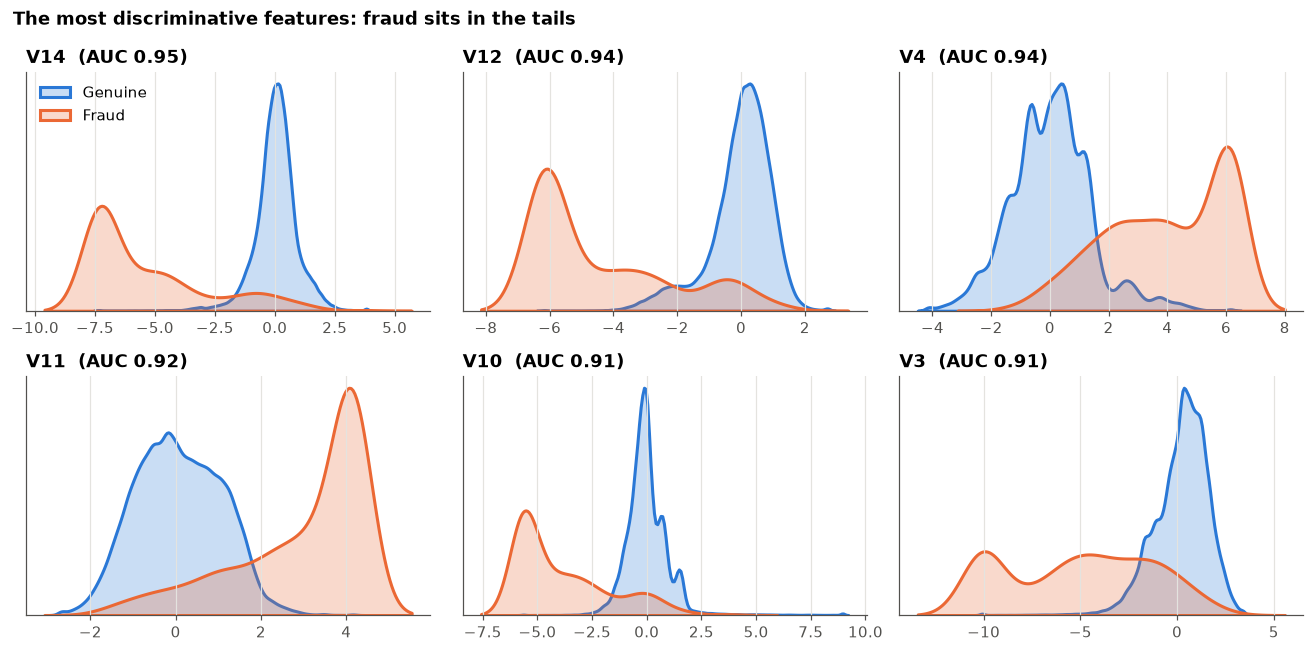

In [6]:
top = separation.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), top):
    lo, hi = train[col].quantile([0.001, 0.999])
    for cls, colour, label in [(0, fu.GENUINE, "Genuine"), (1, fu.FRAUD, "Fraud")]:
        sns.kdeplot(
            train.loc[train["Class"] == cls, col].clip(lo, hi),
            ax=ax, color=colour, fill=True, alpha=0.25, linewidth=2, label=label,
        )
    ax.set_title(f"{col}  (AUC {separation.loc[col, 'univariate AUC']:.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks([])
axes[0, 0].legend(loc="upper left")
fig.suptitle(
    "The most discriminative features: fraud sits in the tails", x=0.01, ha="left",
    fontweight="bold",
)
fig.tight_layout()
fu.savefig(fig, "feature_separation")

Several PCA features (`V14`, `V12`, `V4`, `V11`, `V10`, `V3`) separate the classes strongly on their own: fraud sits in a distinct tail. So there is plenty of signal, and even a linear model should do well. The features are almost uncorrelated with one another (expected for principal components; max |r| = 0.02, see Section 1), so there is no redundancy to remove. We therefore skip feature selection.

### 3.2 Amount and time of day

`Time` counts seconds from the first transaction, so on its own it only says *which of the two days* it is. The hour of day is the meaningful part.

Share of amounts ≤ EUR 1, genuine: 10.5%, fraud: 35.8%
Median amount, genuine: 23.49, fraud: 12.31
Night (0–6h) share of volume: 10.5%, of frauds: 28.8%


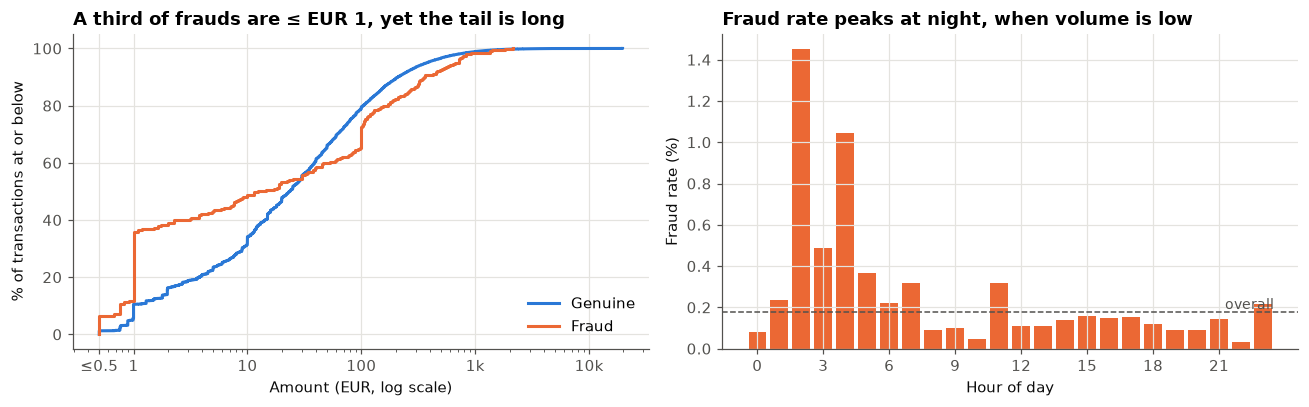

In [7]:
hour = (train["Time"] % 86400 // 3600).astype(int)
by_hour = train.groupby(hour)["Class"].mean() * 100
volume = train.groupby(hour).size()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))

for cls, colour, label in [(0, fu.GENUINE, "Genuine"), (1, fu.FRAUD, "Fraud")]:
    amounts = np.sort(train.loc[train["Class"] == cls, "Amount"].to_numpy())
    share = np.arange(1, len(amounts) + 1) / len(amounts)
    ax1.step(np.maximum(amounts, 0.5), share * 100, where="post", color=colour,
             linewidth=2, label=label)
ax1.set_xscale("log")
ax1.set_xticks([0.5, 1, 10, 100, 1000, 10000], ["≤0.5", "1", "10", "100", "1k", "10k"])
ax1.set_xlabel("Amount (EUR, log scale)")
ax1.set_ylabel("% of transactions at or below")
ax1.set_title("A third of frauds are ≤ EUR 1, yet the tail is long")
ax1.legend(loc="lower right")

ax2.bar(by_hour.index, by_hour.values, color=fu.FRAUD, width=0.8)
ax2.axhline(train["Class"].mean() * 100, color=fu.INK_MUTED, linestyle="--", linewidth=1)
ax2.text(23.5, train["Class"].mean() * 100, " overall", va="bottom", ha="right",
         color=fu.INK_MUTED, fontsize=9)
ax2.set_xlabel("Hour of day")
ax2.set_ylabel("Fraud rate (%)")
ax2.set_xticks(range(0, 24, 3))
ax2.set_title("Fraud rate peaks at night, when volume is low")
fig.tight_layout()
fu.savefig(fig, "amount_and_hour")

print(f"Share of amounts ≤ EUR 1, genuine: {(train.loc[train.Class == 0, 'Amount'] <= 1).mean():.1%}, "
      f"fraud: {(train.loc[train.Class == 1, 'Amount'] <= 1).mean():.1%}")
print(f"Median amount, genuine: {train.loc[train.Class == 0, 'Amount'].median():.2f}, "
      f"fraud: {train.loc[train.Class == 1, 'Amount'].median():.2f}")
print(f"Night (0–6h) share of volume: {volume.loc[0:5].sum() / volume.sum():.1%}, "
      f"of frauds: {train.loc[hour < 6, 'Class'].sum() / train['Class'].sum():.1%}")

* **Amount:** 36% of frauds are for €1 or less (vs. 11% of genuine transactions), which is consistent with *card testing*, where fraudsters check a stolen card with a tiny purchase. Fraud also has a longer tail of large amounts. The distribution is heavily skewed, so models get `log(1 + Amount)`.
* **Hour of day:** the night hours carry a small share of the volume but a disproportionate share of the fraud. We add hour of day as a cyclic feature (sine/cosine), so 23h and 0h are neighbours, and drop raw `Time`.

Both transformations live in `fraud_utils.TimeAmountFeatures` so they run inside the model pipeline.

## 4. Models

### 4.1 Logistic regression

Logistic regression on standardised features is the interpretable baseline. Instead of assuming the usual fixes for imbalanced data work, we test them with forward CV, crossed with the regularisation strength `C` (smaller = stronger L2 penalty):

* **Rebalancing:** none, class weights, SMOTE oversampling, random undersampling. Resamplers sit inside an `imblearn` pipeline, so they only touch training folds.
* **An anomaly score** from an Isolation Forest, added as a feature. `fraud_utils.OutlierScore` fits the detector on training data only. At predict time it just scores rows, so a transaction's score doesn't depend on the batch it is scored with.

In [8]:
lr_pipe = Pipeline(
    [
        ("features", fu.TimeAmountFeatures()),
        ("outlier", "passthrough"),
        ("scale", StandardScaler()),
        ("resample", "passthrough"),
        ("clf", LogisticRegression(max_iter=2000)),
    ]
)
C_grid = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 1e-1, 1]
lr_grid = [
    {"clf__C": C_grid, "resample": ["passthrough", SMOTE(random_state=SEED),
                                    RandomUnderSampler(random_state=SEED)]},
    {"clf__C": C_grid, "clf__class_weight": ["balanced"]},
    {"clf__C": C_grid, "outlier": [fu.OutlierScore()]},
]
lr_search = GridSearchCV(lr_pipe, lr_grid, cv=cv, scoring="average_precision", n_jobs=-1)
lr_search.fit(X_train, y_train)


def lr_variant(params):
    if "outlier" in params:
        return "+ Isolation Forest score"
    if params.get("clf__class_weight") == "balanced":
        return "class weights"
    return {"passthrough": "none", "SMOTE": "SMOTE", "RandomUnderSampler": "undersampling"}[
        params["resample"] if params["resample"] == "passthrough" else type(params["resample"]).__name__
    ]


lr_cv = fu.cv_summary(lr_search)
lr_cv["variant"] = lr_cv["params"].map(lr_variant)
lr_cv["C"] = lr_cv["params"].map(lambda p: p["clf__C"])
lr_cv.pivot(index="C", columns="variant", values="mean_test_score")[
    ["none", "class weights", "SMOTE", "undersampling", "+ Isolation Forest score"]
].style.format("{:.3f}").background_gradient(cmap="Blues", axis=None)

variant,none,class weights,SMOTE,undersampling,+ Isolation Forest score
C,,,,,
0.000100,0.789,0.749,0.742,0.798,0.776
0.000300,0.805,0.709,0.725,0.803,0.795
0.001000,0.804,0.692,0.722,0.806,0.791
0.003000,0.771,0.706,0.739,0.797,0.760
0.010000,0.728,0.723,0.738,0.753,0.728
0.100000,0.663,0.727,0.734,0.513,0.677
1.000000,0.644,0.721,0.725,0.407,0.649


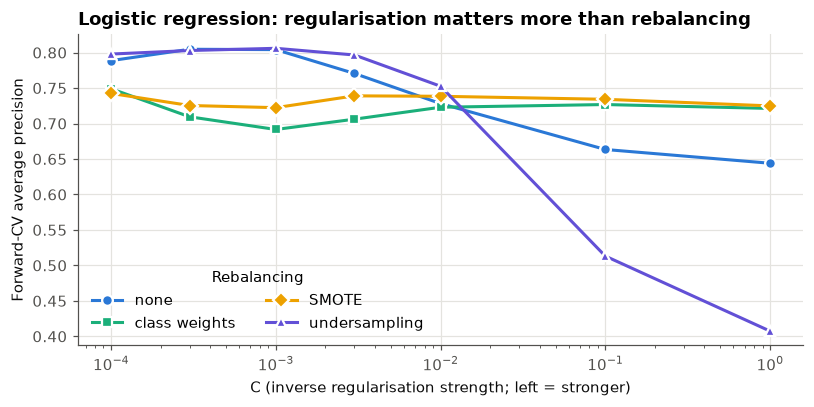

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
styles = [
    ("none", fu.GENUINE, "o"),
    ("class weights", fu.ACCENT, "s"),
    ("SMOTE", "#eda100", "D"),
    ("undersampling", fu.VIOLET, "^"),
]
for variant, colour, marker in styles:
    d = lr_cv[lr_cv["variant"] == variant].sort_values("C")
    ax.plot(d["C"], d["mean_test_score"], color=colour, marker=marker, markersize=7,
            linewidth=2, label=variant, markeredgecolor="white", markeredgewidth=1.5)
ax.set_xscale("log")
ax.set_xlabel("C (inverse regularisation strength; left = stronger)")
ax.set_ylabel("Forward-CV average precision")
ax.set_title("Logistic regression: regularisation matters more than rebalancing")
ax.legend(title="Rebalancing", ncols=2, loc="lower left")
fig.tight_layout()
fu.savefig(fig, "lr_regularisation")

**Regularisation strength is the dominant choice.** With the default `C=1`, the model fits the training period too closely and transfers poorly to the next block. Shrinking the coefficients hard (`C` ≈ 3·10⁻⁴ to 10⁻³) lifts forward-CV AP by about 0.16. Our reading: the fraud signal sits in the extreme tails of a few PCA features. An unregularised model overreacts to the specific extreme values seen in the training period, and strong shrinkage keeps it to the robust *direction* of each feature.

* **Rebalancing** (class weights, SMOTE) only helps where the model is under-regularised, and there its fold-to-fold variance is large. With strong regularisation it adds nothing. Undersampling throws away >99% of genuine transactions and is erratic.
* **The anomaly score** adds nothing the supervised model doesn't already capture.

We keep the best configuration **without any resampling**. It is within noise of the overall best, and simpler.

In [10]:
no_resampling = lr_cv[lr_cv["variant"] == "none"].iloc[0]
overall = lr_cv.iloc[0]
print(f"Best overall:        {overall['variant']:<14} C={overall['C']:g}  "
      f"AP {overall['mean_test_score']:.3f} ± {overall['std_test_score']:.3f}")
print(f"Best, no resampling: {'none':<14} C={no_resampling['C']:g}  "
      f"AP {no_resampling['mean_test_score']:.3f} ± {no_resampling['std_test_score']:.3f}")

lr_model = clone(lr_pipe).set_params(**no_resampling["params"])

Best overall:        undersampling  C=0.001  AP 0.806 ± 0.034
Best, no resampling: none           C=0.0003  AP 0.805 ± 0.033


### 4.2 LightGBM

Gradient-boosted trees can capture non-linear tail behaviour and feature interactions. A randomised search (30 candidates, forward CV) covers the main capacity and regularisation knobs. Two details that are easy to get wrong:

* `subsample` (row bagging) only takes effect in LightGBM when `subsample_freq > 0`, so we fix `subsample_freq=1`.
* `num_leaves`, not `max_depth`, is LightGBM's main capacity control, so we tune that.

Rebalancing is covered by `scale_pos_weight` (1 = none).

In [11]:
lgbm_pipe = Pipeline(
    [
        ("features", fu.TimeAmountFeatures()),
        ("clf", LGBMClassifier(subsample_freq=1, random_state=SEED, n_jobs=1, verbose=-1)),
    ]
)
lgbm_space = {
    "clf__learning_rate": [0.01, 0.02, 0.05, 0.1],
    "clf__n_estimators": [300, 600, 1000],
    "clf__num_leaves": [7, 15, 31, 63],
    "clf__min_child_samples": [20, 50, 100],
    "clf__subsample": [0.6, 0.8, 1.0],
    "clf__colsample_bytree": [0.5, 0.7, 0.9],
    "clf__reg_lambda": [0, 1, 10],
    "clf__scale_pos_weight": [1, 3, 10],
}
lgbm_search = RandomizedSearchCV(
    lgbm_pipe, lgbm_space, n_iter=30, cv=cv, scoring="average_precision",
    n_jobs=-1, random_state=SEED,
)
lgbm_search.fit(X_train, y_train)

search = fu.cv_summary(lgbm_search)
params = pd.json_normalize(search["params"]).rename(columns=lambda c: c.replace("clf__", ""))
search = pd.concat([params, search[["mean_test_score", "std_test_score"]]], axis=1)
search.head(5)

,subsample,scale_pos_weight,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree,mean_test_score,std_test_score
0,0.6,3,10,15,1000,50,0.05,0.7,0.815,0.019
1,0.6,10,10,7,1000,50,0.05,0.7,0.815,0.024
2,1.0,1,10,31,1000,50,0.05,0.5,0.811,0.015
3,1.0,1,0,63,600,20,0.02,0.7,0.810,0.016
4,1.0,1,1,31,300,100,0.02,0.5,0.809,0.018


,count,min,median,max
reg_lambda,,,,
0,7,0.243,0.725,0.810
1,9,0.780,0.798,0.809
10,14,0.789,0.797,0.815


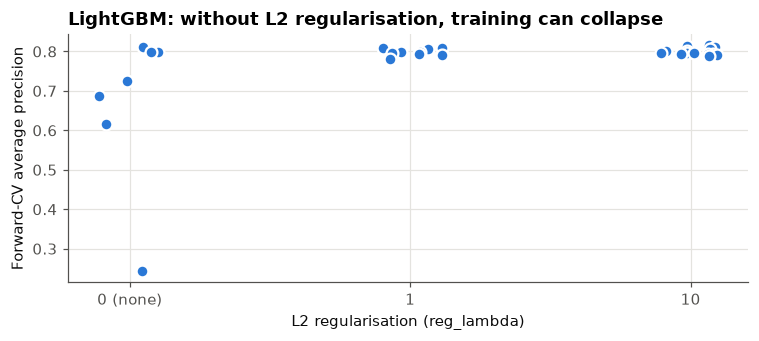

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.2))
jitter = np.random.default_rng(SEED).uniform(-0.12, 0.12, len(search))
x = search["reg_lambda"].map({0: 0, 1: 1, 10: 2}) + jitter
ax.scatter(x, search["mean_test_score"], s=60, color=fu.GENUINE,
           edgecolor="white", linewidth=1.5, zorder=3)
ax.set_xticks([0, 1, 2], ["0 (none)", "1", "10"])
ax.set_xlabel("L2 regularisation (reg_lambda)")
ax.set_ylabel("Forward-CV average precision")
ax.set_title("LightGBM: without L2 regularisation, training can collapse")
fig.tight_layout()
fu.savefig(fig, "lgbm_regularisation")

search.groupby("reg_lambda")["mean_test_score"].agg(["count", "min", "median", "max"])

**The same lesson again: regularisation first.** Without L2 regularisation (`reg_lambda=0`), several configurations collapse, with forward-CV AP as low as 0.24. With only a few hundred positives, unregularised leaf values can blow up on tiny groups of frauds. With `reg_lambda ≥ 1`, *every* configuration lands in a narrow band (≈ 0.78–0.82). Within that band the top candidates are separated by less than one standard deviation, so we simply take the search's best.

### 4.3 Model selection (cross-validation only)

The decision rule, fixed before looking at the test set: pick the model with the higher forward-CV AP. **If the two are within one CV standard deviation of each other, prefer the simpler model.**

In [13]:
lgbm_model = lgbm_search.best_estimator_
best_lgbm = search.iloc[0]

selection = pd.DataFrame(
    {
        "forward-CV AP": [no_resampling["mean_test_score"], best_lgbm["mean_test_score"]],
        "std": [no_resampling["std_test_score"], best_lgbm["std_test_score"]],
    },
    index=["Logistic regression", "LightGBM"],
)
gap = selection.loc["LightGBM", "forward-CV AP"] - selection.loc["Logistic regression", "forward-CV AP"]
within_noise = abs(gap) < selection["std"].max()
selected = "Logistic regression" if within_noise or gap < 0 else "LightGBM"
print(f"LightGBM − LR = {gap:+.3f}; within one std: {within_noise}; selected: {selected}")
selection

LightGBM − LR = +0.011; within one std: True; selected: Logistic regression


,forward-CV AP,std
Logistic regression,0.805,0.033
LightGBM,0.815,0.019


**The two models are statistically tied in cross-validation, so by the rule above logistic regression is selected.** It is simpler to deploy, monitor and explain. LightGBM stays in the comparison as a challenger. Both are scored on the test set below.

## 5. Test-set results

Both models are refit on the full training set and scored once on the held-out final 20% of the timeline. The paired bootstrap scores both models on the same resampled transactions, so it measures the *difference* directly.

In [14]:
lr_model.fit(X_train, y_train)
p_lr = lr_model.predict_proba(X_test)[:, 1]
p_lgbm = lgbm_model.predict_proba(X_test)[:, 1]  # refit=True already trained it on all of X_train

test_rows = {}
for name, p in [("Logistic regression", p_lr), ("LightGBM", p_lgbm)]:
    ap, lo, hi = fu.bootstrap_ci(y_test, p, average_precision_score)
    test_rows[name] = {"test AP": ap, "95% CI low": lo, "95% CI high": hi}
diff = fu.bootstrap_ci(
    y_test, np.c_[p_lgbm, p_lr],
    lambda y, s: average_precision_score(y, s[:, 0]) - average_precision_score(y, s[:, 1]),
)
test_rows["Difference (LightGBM − LR)"] = dict(zip(["test AP", "95% CI low", "95% CI high"], diff))
test_rows["No-skill baseline"] = {"test AP": y_test.mean(), "95% CI low": np.nan, "95% CI high": np.nan}
test_results = pd.DataFrame(test_rows).T
test_results

,test AP,95% CI low,95% CI high
Logistic regression,0.808,0.728,0.893
LightGBM,0.801,0.719,0.887
Difference (LightGBM − LR),-0.008,-0.030,0.013
No-skill baseline,0.001,NaN,NaN


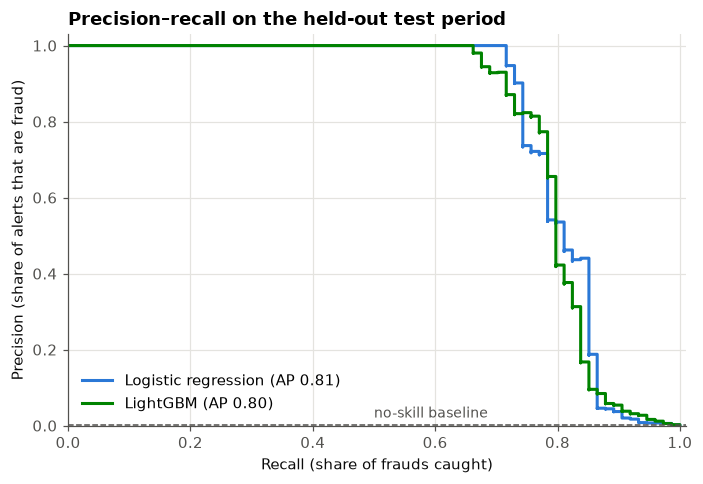

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, p, colour in [("Logistic regression", p_lr, fu.LR_COLOUR), ("LightGBM", p_lgbm, fu.LGBM_COLOUR)]:
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax.step(rec, prec, where="post", color=colour, linewidth=2,
            label=f"{name} (AP {test_results.loc[name, 'test AP']:.2f})")
ax.axhline(y_test.mean(), color=fu.INK_MUTED, linestyle="--", linewidth=1)
ax.text(0.5, y_test.mean() + 0.02, "no-skill baseline", color=fu.INK_MUTED, fontsize=9)
ax.set_xlabel("Recall (share of frauds caught)")
ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.03)
ax.set_title("Precision–recall on the held-out test period")
ax.legend(loc="lower left")
fig.tight_layout()
fu.savefig(fig, "pr_curve_test")

The test period confirms the CV picture: **the two models are indistinguishable.** Both reach a test AP of about 0.8, the paired difference interval straddles zero, and the curves cross repeatedly. Forward CV estimated the test performance of both models well.

### 5.1 Why shuffled cross-validation would have misled us

For comparison, here is what the textbook approach, shuffled stratified K-fold on the training set, reports for the same two models. We also include the default, weakly regularised logistic regression (`C=1`), which the shuffled CV would not have flagged as a problem:

In [16]:
shuffled_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
lr_default = clone(lr_pipe).set_params(clf__C=1.0)
cv_compare = {}
for name, model in [("Logistic regression, C=1", lr_default),
                    ("Logistic regression (selected)", lr_model),
                    ("LightGBM", lgbm_model)]:
    shuffled = cross_validate(model, X_train, y_train, cv=shuffled_cv,
                              scoring="average_precision", n_jobs=-1)["test_score"]
    forward = cross_validate(model, X_train, y_train, cv=cv,
                             scoring="average_precision", n_jobs=-1)["test_score"]
    test_ap = average_precision_score(y_test, clone(model).fit(X_train, y_train).predict_proba(X_test)[:, 1])
    cv_compare[name] = {"shuffled K-fold CV": shuffled.mean(), "forward CV": forward.mean(),
                        "test (later period)": test_ap}
pd.DataFrame(cv_compare).T

,shuffled K-fold CV,forward CV,test (later period)
"Logistic regression, C=1",0.742,0.644,0.753
Logistic regression (selected),0.744,0.805,0.808
LightGBM,0.863,0.815,0.801


Shuffled K-fold puts transactions from the same hour, often from the same fraud burst, on both sides of the split. The flexible model profits most from that: **shuffled CV overstates LightGBM by ≈ 0.05–0.06** and would have shown it beating logistic regression comfortably. It also hides how much the default logistic regression degrades on later data, because shuffled CV scores `C=1` and the selected `C` almost identically. Only the time-ordered evaluation exposes both effects. This is the main methodological takeaway: **for fraud, validate the way the model will be used: past → future.**

## 6. Choosing an operating point

A model outputs a score. The business needs a rule: *alert if score ≥ t*. The default `t = 0.5` is arbitrary, and with strong regularisation the logistic regression's scores are compressed towards the base rate anyway. We choose `t` by minimising an explicit cost:

* each alert costs an analyst review, assumed **€5** (`REVIEW_COST`);
* each missed fraud costs its full **transaction amount**;
* a caught fraud is blocked, so it costs only its review.

The threshold is chosen on **out-of-fold predictions from the forward CV folds** of the training period, never on the test set, and then applied unchanged to the test period. Each of these predictions comes from a model trained only on earlier transactions. We do this for both models.

In [17]:
models = {"Logistic regression": (lr_model, p_lr), "LightGBM": (lgbm_model, p_lgbm)}
oof_preds, oof_curves, thresholds = {}, {}, {}
for name, (model, _) in models.items():
    oof = oof_preds[name] = fu.forward_oof_predict(model, X_train, y_train, cv)
    curve = fu.cost_curve(y_train.loc[oof.index], oof, X_train.loc[oof.index, "Amount"], REVIEW_COST)
    oof_curves[name] = curve
    thresholds[name] = curve.loc[curve["total_cost"].idxmin(), "threshold"]

oof_hours = (X_train.loc[oof.index, "Time"].max() - X_train.loc[oof.index, "Time"].min()) / 3600
pd.DataFrame(
    {name: c.loc[c["total_cost"].idxmin(), ["alerts", "tp", "fp", "fn", "precision", "recall", "total_cost"]]
     for name, c in oof_curves.items()}
).T.assign(**{"alerts per hour": lambda d: d["alerts"] / oof_hours})

,alerts,tp,fp,fn,precision,recall,total_cost,alerts per hour
Logistic regression,284.0,230.0,54.0,66.0,0.810,0.777,12612.53,9.642
LightGBM,256.0,225.0,31.0,71.0,0.879,0.760,12885.60,8.692


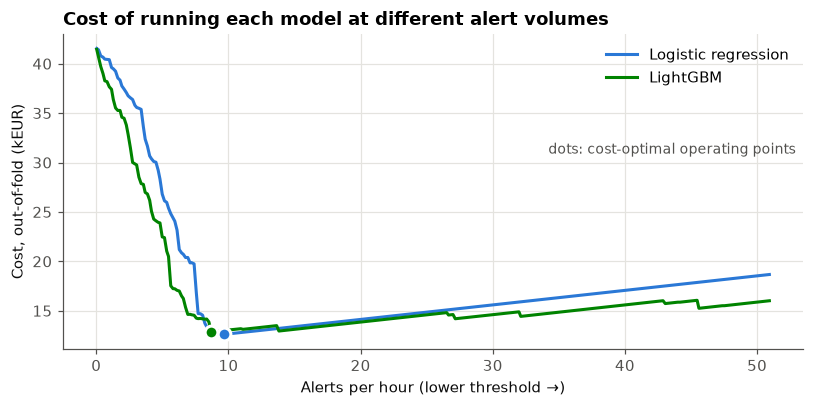

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for name, colour in [("Logistic regression", fu.LR_COLOUR), ("LightGBM", fu.LGBM_COLOUR)]:
    c = oof_curves[name]
    c = c[c["alerts"] <= 1500]
    ax.plot(c["alerts"] / oof_hours, c["total_cost"] / 1000, color=colour, linewidth=2, label=name)
    best = c.loc[c["total_cost"].idxmin()]
    ax.scatter(best["alerts"] / oof_hours, best["total_cost"] / 1000, s=70, color=colour,
               edgecolor="white", linewidth=2, zorder=3)
ax.set_xlabel("Alerts per hour (lower threshold →)")
ax.set_ylabel("Cost, out-of-fold (kEUR)")
ax.set_title("Cost of running each model at different alert volumes")
ax.text(0.99, 0.62, "dots: cost-optimal operating points", transform=ax.transAxes,
        ha="right", color=fu.INK_MUTED, fontsize=9)
ax.legend()
fig.tight_layout()
fu.savefig(fig, "cost_vs_alerts")

Missed frauds dominate the cost, so the optimum sits at a few alerts per hour, and the curve is fairly flat around it. How sensitive is the chosen operating point to the assumed review cost?

In [19]:
oof_lr = oof_preds["Logistic regression"]
sens = {}
for rc in [1, 5, 20, 50]:
    c = fu.cost_curve(y_train.loc[oof_lr.index], oof_lr, X_train.loc[oof_lr.index, "Amount"], rc)
    r = c.loc[c["total_cost"].idxmin()]
    sens[f"EUR {rc}"] = {"alerts per hour": r["alerts"] / oof_hours, "precision": r["precision"],
                         "recall": r["recall"]}
pd.DataFrame(sens).T.rename_axis("review cost (logistic regression)")

,alerts per hour,precision,recall
review cost (logistic regression),,,
EUR 1,9.642,0.81,0.777
EUR 5,9.642,0.81,0.777
EUR 20,8.522,0.90,0.764
EUR 50,8.522,0.90,0.764


Between €1 and €50 per review, the cost-optimal operating point barely moves: about 8.5–9.6 alerts per hour, precision 0.81–0.90 and recall ≈ 0.77. There is a natural gap in the scores between the clear-cut frauds and everything else, and the optimum sits at that gap. The exact review cost should come from the operations team, but the recommendation does not hinge on it.

**Test-period performance at the thresholds chosen on training data** (bootstrap 95% CIs):

In [20]:
y_true = y_test.to_numpy()
amount = X_test["Amount"].to_numpy()
test_hours = (X_test["Time"].max() - X_test["Time"].min()) / 3600
fraud_amount = amount[y_true == 1].sum()

op = {}
for name, (_, p) in models.items():
    alert = p >= thresholds[name]
    prec = fu.bootstrap_ci(y_true, alert, lambda y, a: (a & (y == 1)).sum() / max(a.sum(), 1))
    rec = fu.bootstrap_ci(y_true, alert, lambda y, a: (a & (y == 1)).sum() / (y == 1).sum())
    caught = amount[(y_true == 1) & alert].sum()
    op[name] = {
        "alerts": f"{alert.sum()} (~{alert.sum() / test_hours:.1f} per hour)",
        "frauds caught": f"{(alert & (y_true == 1)).sum()} of {(y_true == 1).sum()}",
        "false alarms": int((alert & (y_true == 0)).sum()),
        "precision": f"{prec[0]:.2f}  [{prec[1]:.2f}, {prec[2]:.2f}]",
        "recall": f"{rec[0]:.2f}  [{rec[1]:.2f}, {rec[2]:.2f}]",
        "fraud value caught": f"EUR {caught:,.0f} of {fraud_amount:,.0f} ({caught / fraud_amount:.0%})",
        "total cost (reviews + missed)": f"EUR {alert.sum() * REVIEW_COST + fraud_amount - caught:,.0f}",
    }
op["No model (miss everything)"] = {"total cost (reviews + missed)": f"EUR {fraud_amount:,.0f}"}
pd.DataFrame(op).fillna("")

,Logistic regression,LightGBM,No model (miss everything)
alerts,79 (~10.3 per hour),64 (~8.4 per hour),
frauds caught,57 of 74,54 of 74,
false alarms,22,10,
precision,"0.72 [0.62, 0.82]","0.84 [0.75, 0.93]",
recall,"0.77 [0.67, 0.87]","0.73 [0.63, 0.83]",
fraud value caught,"EUR 5,327 of 7,728 (69%)","EUR 5,049 of 7,728 (65%)",
total cost (reviews + missed),"EUR 2,796","EUR 2,999","EUR 7,728"


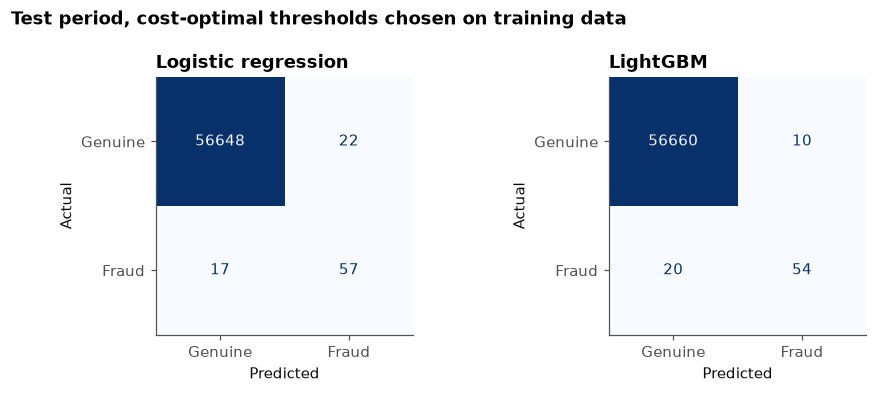

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
for ax, (name, (_, p)) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (p >= thresholds[name]).astype(int), display_labels=["Genuine", "Fraud"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.grid(False)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(name)
fig.suptitle("Test period, cost-optimal thresholds chosen on training data", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
fu.savefig(fig, "confusion_matrix_test")

In the test period (≈ 8 hours, 74 frauds, €7.7k of fraud):

* **Both models cut the cost of fraud by roughly 60–65% versus doing nothing,** at about 8–10 alerts per hour. Logistic regression catches 57 frauds (69% of the fraud value) with 22 false alarms. LightGBM catches 54 (65%) with 10 false alarms. Their total costs (€2.8k vs. €3.0k) are within noise of each other.
* **LightGBM's threshold transferred more cleanly.** Its test precision (0.84) stayed close to its out-of-fold precision (0.88). Logistic regression's dropped from 0.81 to 0.72, so it sent more alerts than planned. With only 74 test frauds the intervals overlap. But if analyst capacity is the binding constraint, this is a point in LightGBM's favour, worth re-checking on more data.

## 7. What drives the predictions

We use **permutation importance on the test set**, which works the same way for both models: how much test AP drops when one feature is shuffled. For logistic regression we also show the coefficients. All features are standardised, so their magnitudes are comparable.

,LR permutation,LightGBM permutation,LR coefficient (standardised)
V14,0.204,0.073,-0.248
V17,0.025,0.001,-0.105
V7,0.022,0.014,-0.037
V4,0.022,0.058,0.110
V10,0.015,0.023,-0.118
V16,0.012,0.008,-0.087
V8,0.007,0.003,-0.044
V3,0.006,0.006,-0.075
V11,0.006,0.020,0.100
V12,0.004,0.037,-0.147


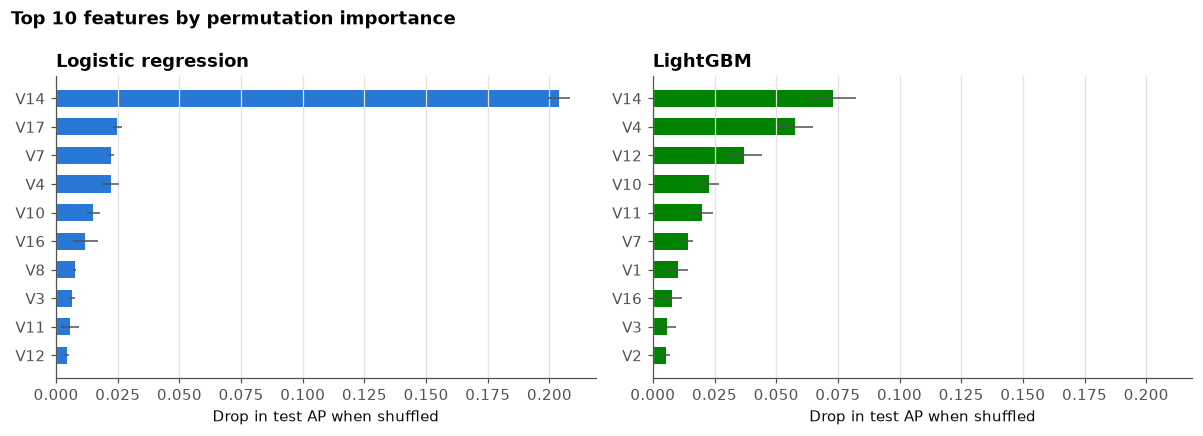

In [22]:
def perm_importance(model):
    r = permutation_importance(model, X_test, y_test, scoring="average_precision",
                               n_repeats=5, random_state=SEED, n_jobs=-1)
    return pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std},
                        index=X_test.columns).sort_values("mean", ascending=False)


importances = {name: perm_importance(model) for name, (model, _) in models.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, (name, imp), colour in zip(axes, importances.items(), [fu.LR_COLOUR, fu.LGBM_COLOUR]):
    top10 = imp.head(10)[::-1]
    ax.barh(top10.index, top10["mean"], xerr=top10["std"], color=colour, height=0.6,
            error_kw=dict(ecolor=fu.INK_MUTED, lw=1))
    ax.set_title(name)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Drop in test AP when shuffled")
fig.suptitle("Top 10 features by permutation importance", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fu.savefig(fig, "permutation_importance")

coefs = pd.Series(lr_model.named_steps["clf"].coef_[0],
                  index=lr_model.named_steps["scale"].get_feature_names_out())
pd.concat(
    {
        "LR permutation": importances["Logistic regression"]["mean"],
        "LightGBM permutation": importances["LightGBM"]["mean"],
        "LR coefficient (standardised)": coefs,
    },
    axis=1,
).sort_values("LR permutation", ascending=False).head(10)

* **Both models rely on the features the exploration flagged:** `V14`, `V4`, `V12`, `V10`, `V11`, `V7`. That consistency is reassuring.
* **Logistic regression leans heavily on `V14`.** Shuffling it alone costs 0.20 AP. Other features carry large coefficients (e.g. `V12`) but add little on top of `V14`: for frauds they carry overlapping information, even though they are uncorrelated over all transactions. **LightGBM spreads its reliance across several features.** That profile is less exposed if any single component's relationship with fraud drifts.
* The engineered hour-of-day and log-amount features don't make either top 10. Once the PCA components are known, they add little.
* The PCA features are anonymised, so we can't translate this into business terms such as merchant type or country. That needs the original features.

## 8. Conclusions and next steps

**Results**

* Both a strongly regularised logistic regression and a tuned LightGBM rank fraud well on a later, unseen period. Test AP is ≈ 0.80 for both, against a no-skill baseline of 0.0013. **They are statistically indistinguishable** in forward CV and on the test set.
* At a cost-optimal threshold chosen on training data only, either model catches about three-quarters of the frauds in the test period at 8–10 alerts per hour. That cuts the cost of fraud by ≈ 60–65% under the stated cost assumptions.

**Recommendation.** Ship the **regularised logistic regression** as the first production model. It performs the same as LightGBM and is simpler to deploy, monitor and explain. Run **LightGBM in shadow mode** as a challenger: its alert precision held up better in the test period and its reliance on features is more diversified, so it may pull ahead with more data.

**What we learned**

1. **Validate past → future.** Shuffled K-fold CV overstated LightGBM and couldn't see that the default logistic regression degrades on later data. Forward CV predicted test performance well for every model.
2. **Regularisation was the single most important modelling choice**, for both models. It mattered far more than any rebalancing technique.
3. **Useful negative results:** SMOTE, undersampling and class weights didn't improve ranking once the model was properly regularised. Undersampling was erratic. An Isolation Forest anomaly score added nothing. Feature selection is unnecessary.

**Limitations**

* Two days of data and 74 test frauds: the intervals are wide, and drift over weeks or months is untested.
* The cost model is deliberately simple. It ignores chargeback recovery, customer friction from false alarms, and analyst capacity limits.
* The features are anonymised, which limits interpretation and feature engineering.

**Next steps**

1. Re-evaluate on a longer time window with rolling (walk-forward) evaluation, and monitor drift in production.
2. Replace the assumed review cost with real figures, and add an alert-capacity constraint.
3. Try a simple ensemble (average of both models' ranks). Their different feature reliance suggests partly different errors.
4. With raw data: card-level aggregates (velocity, amount vs. card history, merchant novelty) usually matter more than any model choice.